# Check how repeatable the runs are

You'll measure two kinds of spread in the sweep, between the processes of one run and between the runs of one setting.
It takes about 10 minutes of your time on a compute node.

## Before you start

Run the kernel inside an allocation and open the full sweep, as in [Measure the flop rate as processes share a node](06-flop-rate-as-processes-share-a-node.ipynb).

In [1]:
from dftracer.utils import Indexer, TraceViewer, col

TRACE = "/usr/workspace/genesis-wisdom/dftracer-traces/genesis-sweep/genesis.pfw.gz"
INDEX = "../data/full-index"
with Indexer(files=[TRACE], index_dir=INDEX) as ix:
    ix.ensure_indexed()
    runs = ix.rowset("runs")
tv = TraceViewer(TRACE, INDEX)
print(runs.shape)

(9624, 10)


In [2]:
import os

import matplotlib.pyplot as plt

os.makedirs("../figures", exist_ok=True)
main = tv.filter((col("gtype") == "func") & (col("path") == "main")).collect().merge(runs, on="run")
main = main.assign(t=main["dur.p50"] / 1e6)

## 1. Spread between the processes of one run

Each process calls `main` once, so `dur.p50` and `dur.p99` of `main` are the median and the slowest processes.
Their ratio is 1 when all processes take the same time.

In [3]:
main = main.assign(spread=main["dur.p99"] / main["dur.p50"])
display(main.groupby(["app", "system"])[["spread"]].quantile(0.99))

,app,system,spread
0,amg,matrix,2.588356
1,amg,tioga,1.158101
2,amg,tuolumne,1.142324
3,laghos,matrix,1.001153
4,laghos,tioga,1.045043
5,minife,tioga,1.521983
6,minife,tuolumne,1.055714


For 99% of the runs of laghos, and of amg on tioga and tuolumne, the slowest process is within about 16% of the median one.
amg on matrix and minife on tioga have runs where it is 1.5 to 2.6 times slower.

## 2. Spread between the runs of one setting

A setting ran once for each counter set, so it has 2 to 9 runs.
They are the same program with the same input, so they should take about the same time.

In [4]:
setting = ["app", "system", "unique_input", "nodes", "ppn"]
g = main.groupby(setting)[["t"]]
rep = g.min().rename(columns={"t": "fastest"}).merge(g.max().rename(columns={"t": "slowest"}), on=setting)
rep = rep.assign(ratio=rep["slowest"] / rep["fastest"])
display(rep.groupby(["app", "system"])[["ratio"]].median())
display(rep.nlargest(5, "ratio"))

,app,system,ratio
0,amg,matrix,1.033971
1,amg,tioga,1.031321
2,amg,tuolumne,1.125494
3,laghos,matrix,1.012806
4,laghos,tioga,1.074222
5,minife,tioga,1.363507
6,minife,tuolumne,1.934835


,app,system,unique_input,nodes,ppn,fastest,slowest,ratio
0,amg,tuolumne,p1_n16x16x8,4,16,0.181762,34.988555,192.496481
1,amg,tuolumne,p1_n16x16x8,4,32,0.276639,42.739568,154.495970
2,amg,tuolumne,p1_n16x16x8,8,32,0.331199,37.162858,112.207146
3,amg,tuolumne,p1_n16x16x8,8,16,0.240497,23.809172,98.999858
4,amg,tuolumne,p1_n16x16x8,4,4,0.069593,6.135249,88.158782


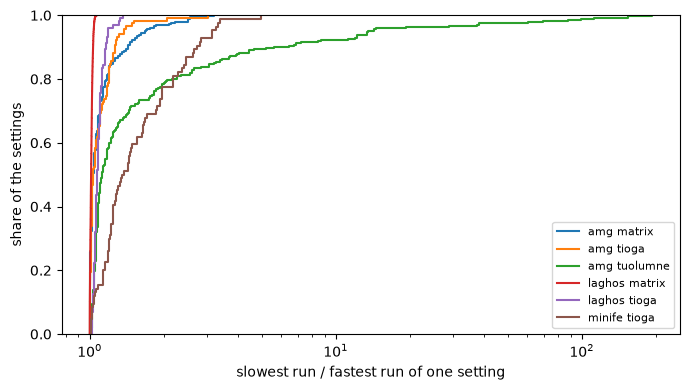

In [5]:
r = rep.to_pandas()
fig, ax = plt.subplots(figsize=(7, 4))
for (app, system), rows in r.groupby(["app", "system"]):
    if len(rows) > 20:
        ax.ecdf(rows["ratio"], label=f"{app} {system}")
ax.set_xscale("log")
ax.set_xlabel("slowest run / fastest run of one setting")
ax.set_ylabel("share of the settings")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig("../figures/run-to-run.png", dpi=120)
plt.show()

For amg on matrix and tioga and for laghos, the runs of one setting are within a few percent of each other in the median.
minife differs more, by about 36% on tioga.
On tuolumne a few amg settings have runs that are up to 192 times slower than the fastest one.

## 3. Look at one slow setting

In [6]:
worst = rep.nlargest(1, "ratio").to_pandas().iloc[0]
same = main[
    (main["app"] == worst["app"])
    & (main["system"] == worst["system"])
    & (main["unique_input"] == worst["unique_input"])
    & (main["nodes"] == worst["nodes"])
    & (main["ppn"] == worst["ppn"])
]
display(same[["run", "papi_set", "t"]].sort_values("t"))

,run,papi_set,t
0,502cc871390f4391,PAPI_FDV_INS+PAPI_FSQ_INS,0.181762
1,e1b0909ae12b40fc,PAPI_FMA_INS+PAPI_FP_INS+PAPI_VEC_INS,0.181762
2,1efda4c3a3d4dd3c,PAPI_TLB_DM+PAPI_TLB_IM,0.181762
3,8308fd4fe7bf0e2d,PAPI_FAD_INS+PAPI_FML_INS,0.185434
4,de7096aebf86d842,PAPI_TOT_CYC+PAPI_TOT_INS,0.189180
5,487e20fbcde2426f,PAPI_L1_DCA+PAPI_L1_DCM+PAPI_L2_DCH+PAPI_L2_DCM+PAPI_L2_DCR+PAPI_L2_ICM+PAPI_L2_TCM,0.192762
6,f4ea39c86b3b0873,PAPI_L2_ICA+PAPI_L2_ICH+PAPI_L2_ICR+PAPI_L2_TCH,0.193002
7,5912c9b05e7abb62,PAPI_BR_CN+PAPI_BR_INS+PAPI_BR_MSP+PAPI_BR_NTK+PAPI_BR_PRC+PAPI_BR_TKN+PAPI_BR_UCN,34.290002
8,c386cb27d77f9c1e,PAPI_FP_OPS,34.988555


Over all such settings the slow runs come from at least five different counter sets, so no one counter set makes them slow.
[Read the host counters of each run](12-host-counters.ipynb) shows that the host CPU counters don't explain them either.

## What you built

You measured the spread between processes and between runs, and found the settings whose runs disagree.

- Next: [Read merged distributions](10-merged-distributions.ipynb)